In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
brands_path = "./brands.csv"
categories_path = "./categories.csv"
customers_path = "./customers.csv"
orders_path = "./orders.csv"
order_items_path = "./order_items.csv"
products_path = "./products.csv"
staffs_path = "./staffs.csv"
stores_path = "./stores.csv"
stocks_path = "./stocks.csv"



brands_df = pd.read_csv(brands_path)
categories_df = pd.read_csv(categories_path)
customers_df = pd.read_csv(customers_path)
orders_df = pd.read_csv(orders_path, parse_dates=['order_date', 'required_date', 'shipped_date'])
order_items_df = pd.read_csv(order_items_path)
products_df = pd.read_csv(products_path)
staffs_df = pd.read_csv(staffs_path)
stores_df = pd.read_csv(stores_path)
stocks_df = pd.read_csv(stocks_path)

In [4]:
# brands_df
# categories_df
# customers_df['phone']= customers_df['phone'].fillna('no phone number')
# customers_df.isnull().sum()
# orders_df.info()

# order_items_df
# products_df.drop(columns=['list_price'], inplace=True)
# staffs_df
# stores_df
# stocks_df

In [5]:
order_items_df['sales'] = order_items_df['quantity']*order_items_df['list_price']*(1-order_items_df['discount'])


In [6]:
products_df

,product_id,product_name,brand_id,category_id,model_year,list_price
0,1,Trek 820 - 2016,9,6,2016,379.99
1,2,Ritchey Timberwolf Frameset - 2016,5,6,2016,749.99
2,3,Surly Wednesday Frameset - 2016,8,6,2016,999.99
3,4,Trek Fuel EX 8 29 - 2016,9,6,2016,2899.99
4,5,Heller Shagamaw Frame - 2016,3,6,2016,1320.99
...,...,...,...,...,...,...
316,317,Trek Checkpoint ALR 5 - 2019,9,7,2019,1999.99
317,318,Trek Checkpoint ALR 5 Women's - 2019,9,7,2019,1999.99
318,319,Trek Checkpoint SL 5 Women's - 2019,9,7,2019,2799.99
319,320,Trek Checkpoint SL 6 - 2019,9,7,2019,3799.99


In [7]:
brands_df[brands_df.duplicated()]

,brand_id,brand_name


In [8]:
order_items_df['profit'] = order_items_df['sales'] - (order_items_df['quantity']*order_items_df['discount']*100)
order_items_df

,order_id,item_id,product_id,quantity,list_price,discount,sales,profit
0,1,1,20,1,599.99,0.20,479.9920,459.9920
1,1,2,8,2,1799.99,0.07,3347.9814,3333.9814
2,1,3,10,2,1549.00,0.05,2943.1000,2933.1000
3,1,4,16,2,599.99,0.05,1139.9810,1129.9810
4,1,5,4,1,2899.99,0.20,2319.9920,2299.9920
...,...,...,...,...,...,...,...,...
4717,1614,2,159,2,2299.99,0.07,4277.9814,4263.9814
4718,1614,3,213,2,269.99,0.20,431.9840,391.9840
4719,1615,1,197,2,2299.99,0.20,3679.9840,3639.9840
4720,1615,2,214,1,899.99,0.07,836.9907,829.9907


In [9]:
order_items_df['discount_value'] = order_items_df['quantity']* order_items_df['list_price']*order_items_df['list_price']*order_items_df['discount']
order_items_df

,order_id,item_id,product_id,quantity,list_price,discount,sales,profit,discount_value
0,1,1,20,1,599.99,0.20,479.9920,459.9920,7.199760e+04
1,1,2,8,2,1799.99,0.07,3347.9814,3333.9814,4.535950e+05
2,1,3,10,2,1549.00,0.05,2943.1000,2933.1000,2.399401e+05
3,1,4,16,2,599.99,0.05,1139.9810,1129.9810,3.599880e+04
4,1,5,4,1,2899.99,0.20,2319.9920,2299.9920,1.681988e+06
...,...,...,...,...,...,...,...,...,...
4717,1614,2,159,2,2299.99,0.07,4277.9814,4263.9814,7.405936e+05
4718,1614,3,213,2,269.99,0.20,431.9840,391.9840,2.915784e+04
4719,1615,1,197,2,2299.99,0.20,3679.9840,3639.9840,2.115982e+06
4720,1615,2,214,1,899.99,0.07,836.9907,829.9907,5.669874e+04


In [10]:
orders_df['shipping_days'] = (orders_df['shipped_date'] - orders_df['order_date']).dt.days
orders_df

,order_id,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id,shipping_days
0,1,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2.0
1,2,1212,4,2016-01-01,2016-01-04,2016-01-03,2,6,2.0
2,3,523,4,2016-01-02,2016-01-05,2016-01-03,2,7,1.0
3,4,175,4,2016-01-03,2016-01-04,2016-01-05,1,3,2.0
4,5,1324,4,2016-01-03,2016-01-06,2016-01-06,2,6,3.0
...,...,...,...,...,...,...,...,...,...
1610,1611,6,3,2018-09-06,2018-09-06,NaT,2,7,NaN
1611,1612,3,3,2018-10-21,2018-10-21,NaT,1,3,NaN
1612,1613,1,3,2018-11-18,2018-11-18,NaT,2,6,NaN
1613,1614,135,3,2018-11-28,2018-11-28,NaT,3,8,NaN


In [11]:
cancelled_orders = orders_df[orders_df['shipped_date'].isnull()]
total_cancelled_orders =len(cancelled_orders)
total_cancelled_orders
estimated_loss = cancelled_orders.merge(order_items_df, on='order_id', how='left')['sales'].sum()
estimated_loss

np.float64(1026501.3134999999)

In [12]:
kpi = {
    "total_sales": order_items_df['sales'].sum()-estimated_loss,
    "total_profit": order_items_df['discount_value'].sum(),
    "avg_discount": order_items_df['discount'].sum()/len(orders_df),
    "avg_shipping_days": orders_df['shipping_days'].mean(),
    "potential sales loss":estimated_loss
    
}
kpi

{'total_sales': np.float64(6662615.2441),
 'total_profit': np.float64(2358976018.0494757),
 'avg_discount': np.float64(0.308092879256966),
 'avg_shipping_days': np.float64(1.9820069204152249),
 'potential sales loss': np.float64(1026501.3134999999)}

In [13]:
temp_order = order_items_df.merge(orders_df)
placed_order_table = temp_order[~temp_order["shipped_date"].isna()]
placed_order_table["order_month"] = placed_order_table["order_date"].dt.month_name()
placed_order_table["order_year"] = placed_order_table["order_date"].dt.year

In [14]:
placed_order_table

,order_id,item_id,product_id,quantity,list_price,discount,sales,profit,discount_value,customer_id,order_status,order_date,required_date,shipped_date,store_id,staff_id,shipping_days,order_month,order_year
0,1,1,20,1,599.99,0.20,479.9920,459.9920,7.199760e+04,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016
1,1,2,8,2,1799.99,0.07,3347.9814,3333.9814,4.535950e+05,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016
2,1,3,10,2,1549.00,0.05,2943.1000,2933.1000,2.399401e+05,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016
3,1,4,16,2,599.99,0.05,1139.9810,1129.9810,3.599880e+04,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016
4,1,5,4,1,2899.99,0.20,2319.9920,2299.9920,1.681988e+06,259,4,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4300,1476,4,191,1,2799.99,0.10,2519.9910,2509.9910,7.839944e+05,35,4,2018-03-31,2018-04-01,2018-04-01,2,7,1.0,March,2018
4301,1476,5,265,2,289.99,0.10,521.9820,501.9820,1.681884e+04,35,4,2018-03-31,2018-04-01,2018-04-01,2,7,1.0,March,2018
4302,1477,1,210,2,1549.00,0.20,2478.4000,2438.4000,9.597604e+05,180,4,2018-03-31,2018-04-03,2018-04-01,2,6,1.0,March,2018
4303,1478,1,100,2,489.99,0.10,881.9820,861.9820,4.801804e+04,392,4,2018-03-31,2018-04-02,2018-04-02,2,6,2.0,March,2018


In [15]:
year_month_sales = placed_order_table.pivot_table(
    index="order_year",
    columns="order_month",
    values="sales",
    aggfunc="sum"
)
year_month_sales

order_month,April,August,December,February,January,July,June,March,May,November,October,September
order_year,,,,,,,,,,,,
2016,164399.0787,212827.1116,189684.6858,148506.3581,215146.4241,199556.8089,205463.9801,180600.3285,197179.0947,176050.5680,212078.0805,271356.6772
2017,220409.1576,273336.5895,259505.9849,281968.3049,285616.4840,213719.7002,375577.5307,308157.4203,263044.7562,268809.1281,303422.3366,293405.2561
2018,NaN,NaN,NaN,197372.3060,381430.0993,NaN,NaN,363990.9935,NaN,NaN,NaN,NaN


<Axes: xlabel='order_month', ylabel='order_year'>

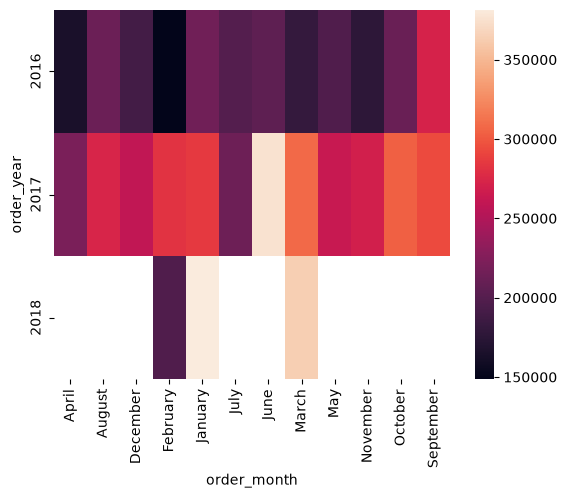

In [16]:
sns.heatmap(year_month_sales)

<Figure size 1500x500 with 0 Axes>

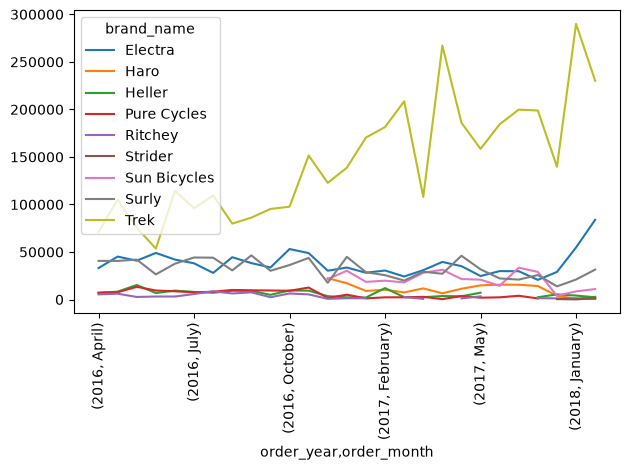

In [17]:
brand_year_month_sales = placed_order_table.merge(products_df).merge(brands_df).pivot_table(
    index=["order_year","order_month"],
    columns="brand_name",
    values="sales",
    aggfunc="sum"
)
brand_year_month_sales
plt.figure(figsize=(15,5))
brand_year_month_sales.plot()
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

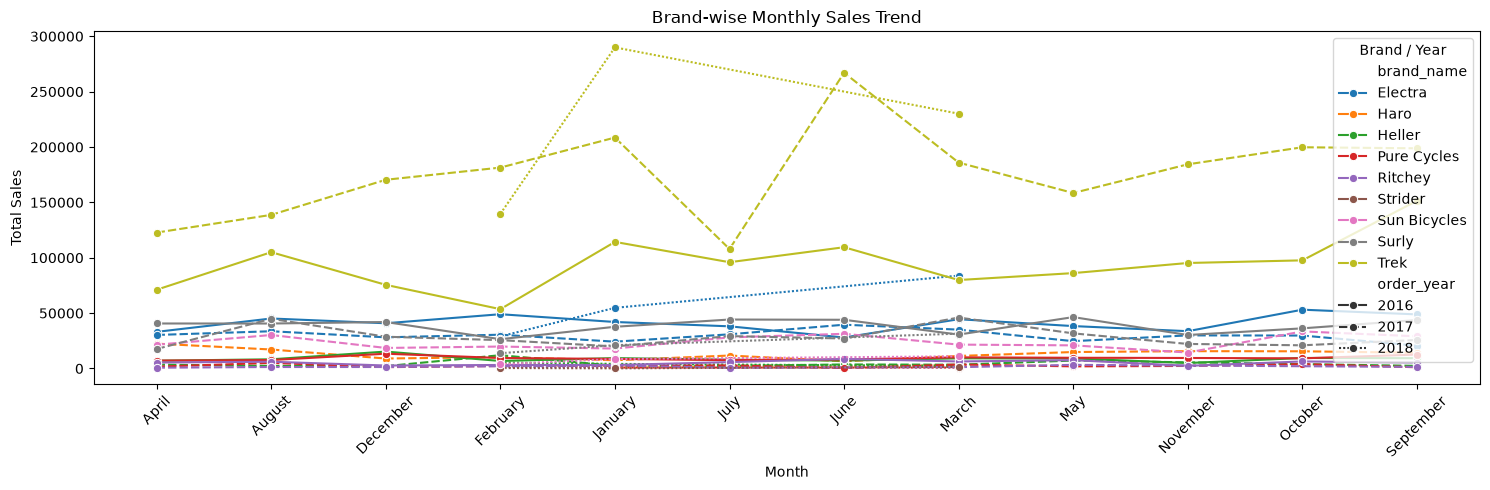

In [18]:
brand_sales = (
    placed_order_table
    .merge(products_df)
    .merge(brands_df)
)

brand_year_month_sales = brand_sales.pivot_table(
    index=["order_year", "order_month"],
    columns="brand_name",
    values="sales",
    aggfunc="sum"
)

brand_sales_long = brand_year_month_sales.reset_index().melt(
    id_vars=["order_year", "order_month"],
    var_name="brand_name",
    value_name="total_sales"
)

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

sns.lineplot(
    data=brand_sales_long,
    x="order_month",
    y="total_sales",
    hue="brand_name",
    style="order_year",
    marker="o"
)

plt.title("Brand-wise Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Brand / Year")
plt.tight_layout()
plt.show()

In [19]:
def month_no(month_name):
    month_dict = {
        "January": 1,
        "February": 2,
        "March": 3,
        "April": 4,
        "May": 5,
        "June": 6,
        "July": 7,
        "August": 8,
        "September": 9,
        "October": 10,
        "November": 11,
        "December": 12
    }
    return month_dict[month_name]






In [20]:
df = placed_order_table.copy()

In [21]:
def month_no(month_name):
    month_dict = {
        "January": 1,
        "February": 2,
        "March": 3,
        "April": 4,
        "May": 5,
        "June": 6,
        "July": 7,
        "August": 8,
        "September": 9,
        "October": 10,
        "November": 11,
        "December": 12
    }
    return month_dict[month_name]

In [22]:
df["month_no"] = df["order_month"].apply(month_no)

df["year_month"] = (
    df["order_year"].astype(str) + "-" +
    df["month_no"].astype(str).str.zfill(2)
)

df

,order_id,item_id,product_id,quantity,list_price,discount,sales,profit,discount_value,customer_id,...,order_date,required_date,shipped_date,store_id,staff_id,shipping_days,order_month,order_year,month_no,year_month
0,1,1,20,1,599.99,0.20,479.9920,459.9920,7.199760e+04,259,...,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016,1,2016-01
1,1,2,8,2,1799.99,0.07,3347.9814,3333.9814,4.535950e+05,259,...,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016,1,2016-01
2,1,3,10,2,1549.00,0.05,2943.1000,2933.1000,2.399401e+05,259,...,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016,1,2016-01
3,1,4,16,2,599.99,0.05,1139.9810,1129.9810,3.599880e+04,259,...,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016,1,2016-01
4,1,5,4,1,2899.99,0.20,2319.9920,2299.9920,1.681988e+06,259,...,2016-01-01,2016-01-03,2016-01-03,1,2,2.0,January,2016,1,2016-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4300,1476,4,191,1,2799.99,0.10,2519.9910,2509.9910,7.839944e+05,35,...,2018-03-31,2018-04-01,2018-04-01,2,7,1.0,March,2018,3,2018-03
4301,1476,5,265,2,289.99,0.10,521.9820,501.9820,1.681884e+04,35,...,2018-03-31,2018-04-01,2018-04-01,2,7,1.0,March,2018,3,2018-03
4302,1477,1,210,2,1549.00,0.20,2478.4000,2438.4000,9.597604e+05,180,...,2018-03-31,2018-04-03,2018-04-01,2,6,1.0,March,2018,3,2018-03
4303,1478,1,100,2,489.99,0.10,881.9820,861.9820,4.801804e+04,392,...,2018-03-31,2018-04-02,2018-04-02,2,6,2.0,March,2018,3,2018-03


<Axes: title={'center': 'Sales by Category'}, xlabel='category_name'>

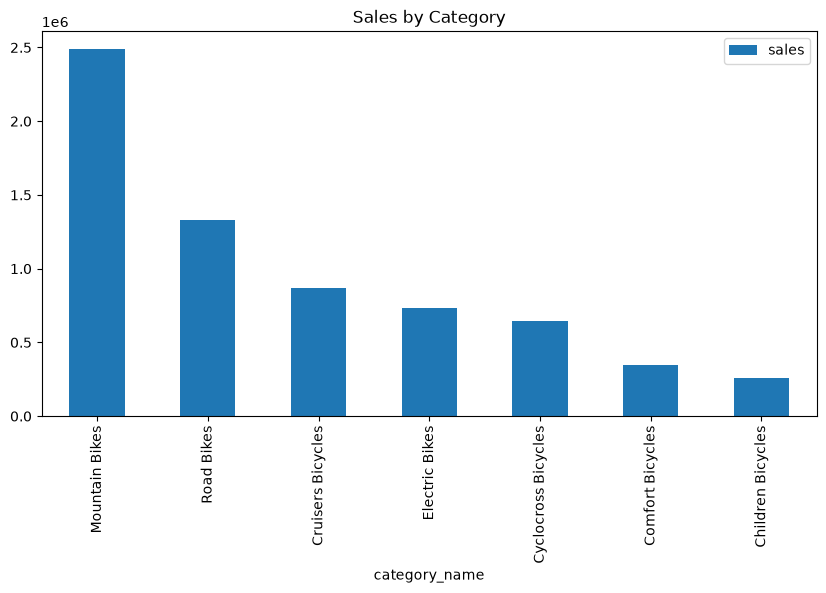

In [23]:
placed_order_table.merge(products_df).merge(categories_df).pivot_table(
    index="category_name",
     values="sales",
    aggfunc="sum"
).sort_values(by="sales", ascending=False).plot(kind="bar", figsize=(10, 5), title="Sales by Category")


In [ ]:

store_salesstore_sales = placed_order_table.merge(stores_df).pivot_table(
    index="store_name",
    values="sales",
    aggfunc="sum"
).sort_values(by="sales", ascending=False).reset_index()

,store_name,sales
0,Baldwin Bikes,4.701210e+06
1,Santa Cruz Bikes,1.255492e+06
2,Rowlett Bikes,7.059140e+05


<Axes: title={'center': 'Price vs Sales Scatter Plot'}, xlabel='list_price', ylabel='sales'>

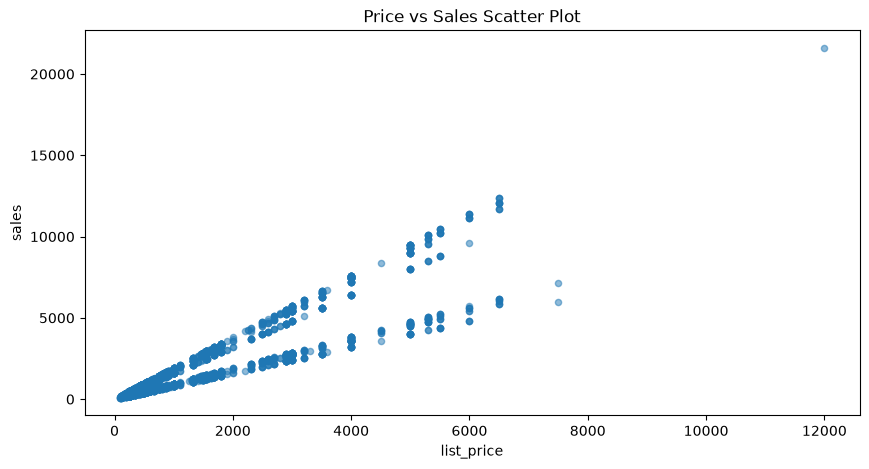

In [25]:
# price vs sales scatter plot
price_sales_df = placed_order_table.merge(products_df)
price_sales_df.plot.scatter(x="list_price", y="sales", alpha=0.5, figsize=(10, 5), title="Price vs Sales Scatter Plot")